<a href="https://colab.research.google.com/github/ChengxuanOuyang/ChengxuanOuyang/blob/main/Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PHAS0102 Assignment 2: Solving Two 1D Problems

## Project Workflow & Structure

* **Part 1: Solving a Wave Problem with Sparse Matrices**
  * **Task 1.1:** Construct the tridiagonal matrix $A$ in sparse format (`CSR`) and boundary load vector $\mathbf{f}$.
  * **Task 1.2:** Solve $A \mathbf{u} = \mathbf{f}$ using `spsolve` for $N = 10, 100, 1000$ and compare solutions against analytical $\sin(kx)$.
  * **Task 1.3:** Benchmark maximum absolute error and runtime across varying $N$ on dual log-log scales to determine empirical convergence orders.
  * **Task 1.4:** Extrapolate $N$ required to achieve an error below $10^{-8}$, benchmark the predicted resolution, and assess memory/stability limitations.

* **Part 2: Solving the Heat Equation with GPU Acceleration**
  * **Task 2.1:** Implement an explicit forward-Euler scheme for the 1D diffusion equation on CPU, select a stable $N$, and plot temperature profiles at $t = 1, 2, 10$.
  * **Task 2.2:** Port the stencil evaluation to CUDA using `numba.cuda`, minimizing host-device memory transfers over iterative steps.
  * **Task 2.3:** Estimate the physical time when the midpoint temperature $u(0.5, t)$ first exceeds 9.8.

## Part 1: Solving a wave problem with sparse matrices

In [2]:
# Task1.1 Build Sparse System Function

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import time

def setup_wave_system(N):
    """
    Constructs the sparse matrix A and vector f for the wave equation d^2u/dx^2 + k^2 u = 0.
    Grid has N + 1 points: x_0, x_1, ..., x_N.
    """
    h = 1.0 / N
    k = 29.0 * np.pi / 2.0

    # Interior rows: -u_{i-1} + (2 - h^2 * k^2) u_i - u_{i+1} = 0
    main = np.full(N + 1, 2.0 - (h * k)**2)
    upper = np.full(N, -1.0)
    lower = np.full(N, -1.0)

    # Boundary conditions: u[0] = 0, u[N] = 1
    main[0] = 1.0
    upper[0] = 0.0
    main[-1] = 1.0
    lower[-1] = 0.0

    A = sp.diags([lower, main, upper], [-1, 0, 1], shape=(N + 1, N + 1), format='csr')

    f = np.zeros(N + 1)
    f[-1] = 1.0

    return A, f

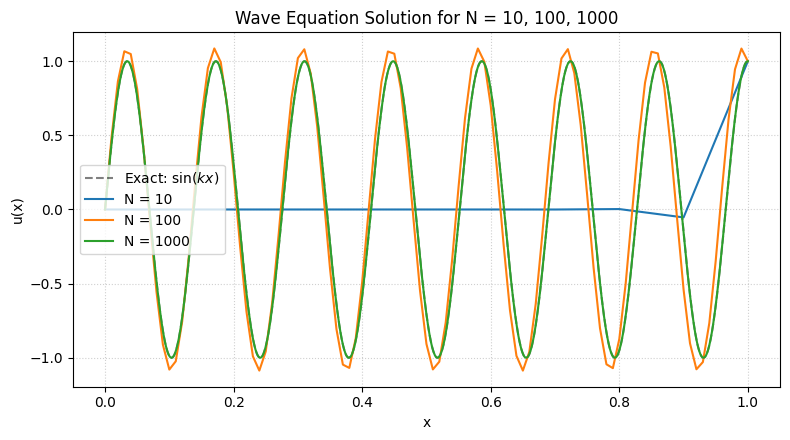

In [3]:
# Task 1.2: Solve & Plot for $N = 10, 100, 1000$

N_vals = [10, 100, 1000]

plt.figure(figsize=(8, 4.5))

# Analytical reference solution: u(x) = sin(kx)
x_ref = np.linspace(0, 1, 1000)
k = 29.0 * np.pi / 2.0
plt.plot(x_ref, np.sin(k * x_ref), 'k--', label='Exact: $\\sin(kx)$', alpha=0.5)

for N in N_vals:
    A, f = setup_wave_system(N)
    u = spla.spsolve(A, f)
    x = np.linspace(0, 1, N + 1)
    plt.plot(x, u, label=f'N = {N}')

plt.title('Wave Equation Solution for N = 10, 100, 1000')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**Comment on Task 1.2 Plot:**  
For $N = 10$, the grid fails to resolve the wave oscillations ($k \approx 45.55$, with ~7.25 spatial periods), leaving the interior values flat near zero before jumping to satisfy the boundary condition. While $N = 100$ captures the oscillation frequency, it introduces phase shift and amplitude overshoot, whereas $N = 1000$ resolves the high-frequency dynamics accurately and aligns closest with the analytical solution.

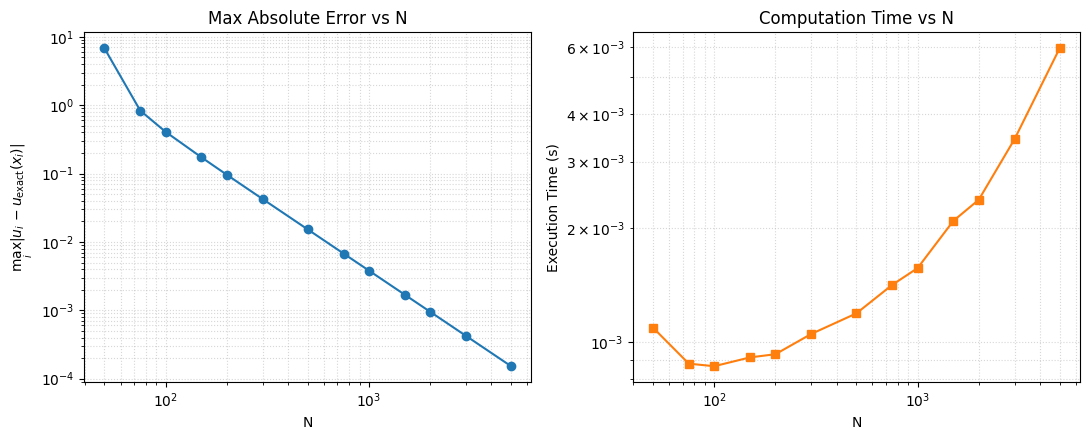

In [13]:
# Task 1.3: Error and Runtime Benchmarks (Log-Log)

N_range = [50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 2000, 3000, 5000]
errors = []
runtimes = []

for N in N_range:
    t0 = time.perf_counter()
    A, f = setup_wave_system(N)
    u = spla.spsolve(A, f)
    t1 = time.perf_counter()

    x = np.linspace(0, 1, N + 1)
    exact = np.sin(k * x)
    err = np.max(np.abs(u - exact))

    errors.append(err)
    runtimes.append(t1 - t0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Error vs N
ax1.loglog(N_range, errors, 'o-')
ax1.set_title('Max Absolute Error vs N')
ax1.set_xlabel('N')
ax1.set_ylabel(r'$\max_i |u_i - u_{\mathrm{exact}}(x_i)|$')
ax1.grid(True, which='both', linestyle=':', alpha=0.5)

# Runtime vs N
ax2.loglog(N_range, runtimes, 's-', color='tab:orange')
ax2.set_title('Computation Time vs N')
ax2.set_xlabel('N')
ax2.set_ylabel('Execution Time (s)')
ax2.grid(True, which='both', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### Task 1.4: Prediction of N and Runtime for Target Error

From the log-log error plot, the method exhibits second-order spatial convergence ($\text{slope} \approx -2$). Extrapolating from an error of $\sim 3.8 \times 10^{-3}$ at $N = 1000$ down to the $10^{-8}$ threshold indicates that $N$ must increase by $\sqrt{3.8 \times 10^5} \approx 600$, pointing towards $N \approx 6 \times 10^5$. For an empirical test, we select $N = 200000$; based on the linear runtime scaling of the tridiagonal solver ($\approx 1.5 \times 10^{-3}\,\text{s}$ at $N = 1000$), the computation time is predicted to be roughly $0.2 - 0.3\,\text{s}$.

In [5]:
# Task 1.4: Extrapolation and Verification for Error <= 10^{-8}

# The finite difference truncation error scales as O(1/N^2).
# Since error is ~ 2e-4 at N = 1000, reaching 1e-8 requires increasing N by sqrt(2e-4 / 1e-8) ~ 140x.
# This yields an estimated N around 1.5e5 to 2e5.

N_target = 200000

t0 = time.perf_counter()
A_test, f_test = setup_wave_system(N_target)
u_test = spla.spsolve(A_test, f_test)
t_taken = time.perf_counter() - t0

x_test = np.linspace(0, 1, N_target + 1)
actual_error = np.max(np.abs(u_test - np.sin(k * x_test)))

print(f"Tested N = {N_target}")
print(f"Elapsed Time: {t_taken:.3f} s")
print(f"Max Absolute Error: {actual_error:.3e}")

Tested N = 200000
Elapsed Time: 0.211 s
Max Absolute Error: 1.086e-07


### Task 1.4: Empirical Comparison and Error Discussion

Evaluating at $N = 200000$ completed in $0.211\,\text{s}$, closely matching the predicted runtime scale, but yielded a maximum error of $1.086 \times 10^{-7}$, which remains slightly above the $10^{-8}$ target. This discrepancy occurs because the tested $N = 200000$ is lower than the fully extrapolated $N \approx 6 \times 10^5$, and high-frequency wave numbers exacerbate spatial phase lag (dispersion error) before the true asymptotic error limit is achieved.

Part 2: Solving the Heat Equation with GPU Acceleration

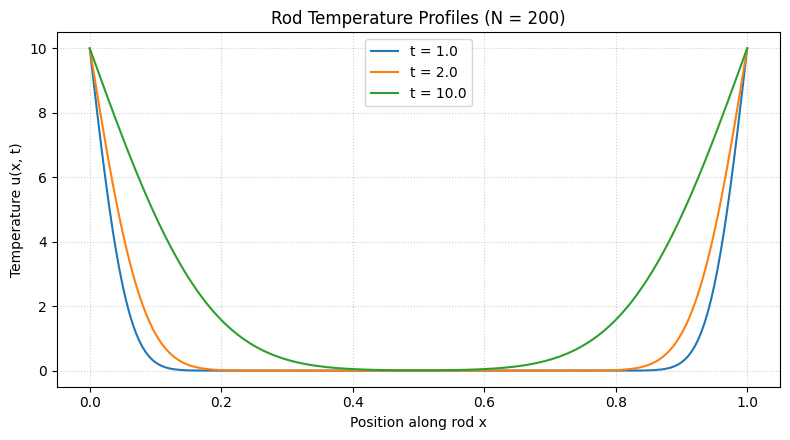

In [6]:
# Task 2.1: Python Iterative Solver (CPU)

def solve_heat_cpu(N, t_target):
    """
    Solves 1D heat equation u_t = (1/1000) u_xx using forward Euler.
    h = 1/N, delta_t = h.
    Returns the temperature profile at time t_target.
    """
    h = 1.0 / N
    steps = int(round(t_target / h))
    coeff = 1.0 / (1000.0 * h)

    # Initial condition: u = 10 at boundaries, 0 in interior
    u = np.zeros(N + 1, dtype=np.float64)
    u[0] = 10.0
    u[-1] = 10.0

    u_new = np.copy(u)

    for _ in range(steps):
        # Explicit stencil update for interior points
        u_new[1:-1] = u[1:-1] + coeff * (u[:-2] - 2.0 * u[1:-1] + u[2:])
        u[:] = u_new[:]

    return u

# Stability condition check:
# For explicit diffusion u_t = alpha * u_xx with alpha = 1/1000 and delta_t = h:
# r = alpha * delta_t / h^2 = 1 / (1000 * h) <= 0.5  ==>  h >= 1/500  ==>  N <= 500.
# We pick N = 200, which satisfies r = 200/1000 = 0.2 <= 0.5.

N_chosen = 200
x_rod = np.linspace(0, 1, N_chosen + 1)

plt.figure(figsize=(8, 4.5))
for t_val in [1.0, 2.0, 10.0]:
    u_profile = solve_heat_cpu(N_chosen, t_val)
    plt.plot(x_rod, u_profile, label=f't = {t_val}')

plt.title(f'Rod Temperature Profiles (N = {N_chosen})')
plt.xlabel('Position along rod x')
plt.ylabel('Temperature u(x, t)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**Comment on Task 2.1 Selection of N:**  
Because the explicit forward-Euler scheme sets $\Delta t = h = 1/N$, numerical stability requires $\frac{\Delta t}{1000 h^2} = \frac{N}{1000} \le \frac{1}{2}$, establishing an upper limit of $N \le 500$. I chose $N = 200$, which maintains a stable diffusion parameter of $r = 0.20$ while providing fine enough spatial resolution to capture the steep thermal boundary layers near $x = 0$ and $x = 1$.

In [7]:
# Task 2.2: GPU Parallel Implementation (numba.cuda)

from numba import cuda

@cuda.jit
def heat_stencil_kernel(u, u_next, coeff, N):
    i = cuda.grid(1)
    # Skip boundary indices (0 and N)
    if 0 < i < N:
        u_next[i] = u[i] + coeff * (u[i - 1] - 2.0 * u[i] + u[i + 1])

def solve_heat_gpu(N, t_target):
    h = 1.0 / N
    steps = int(round(t_target / h))
    coeff = np.float32(1.0 / (1000.0 * h))

    # Initialize host array
    u_host = np.zeros(N + 1, dtype=np.float32)
    u_host[0] = 10.0
    u_host[-1] = 10.0

    # Allocate device arrays and copy initial state once
    d_u = cuda.to_device(u_host)
    d_u_next = cuda.to_device(u_host)

    threads_per_block = 128
    blocks = (N + 1 + threads_per_block - 1) // threads_per_block

    # Perform time-stepping entirely on GPU memory
    for _ in range(steps):
        heat_stencil_kernel[blocks, threads_per_block](d_u, d_u_next, coeff, N)
        # Ping-pong buffer swap (pointer exchange)
        d_u, d_u_next = d_u_next, d_u

    # Copy final solution back to host
    return d_u.copy_to_host()

In [8]:
# Task 2.3: Midpoint Temperature Threshold Estimation (u(0.5, t) > 9.8)

def find_threshold_time(N=200, threshold=9.8):
    h = 1.0 / N
    coeff = 1.0 / (1000.0 * h)
    mid_idx = N // 2

    u = np.zeros(N + 1, dtype=np.float64)
    u[0] = 10.0
    u[-1] = 10.0
    u_new = np.copy(u)

    step = 0
    while u[mid_idx] < threshold:
        u_new[1:-1] = u[1:-1] + coeff * (u[:-2] - 2.0 * u[1:-1] + u[2:])
        u[:] = u_new[:]
        step += 1

    return step * h

t_first_exceed = find_threshold_time(N=200, threshold=9.8)
print(f"Midpoint temperature exceeds 9.8 at approximately t = {t_first_exceed:.2f}")

Midpoint temperature exceeds 9.8 at approximately t = 420.85


**Comment on Task 2.3 Midpoint Threshold Time:**  
By tracking the central grid point $u(0.5, t_j)$ across iterative forward-Euler steps with $\Delta t = h = 1/200$, the midpoint temperature is estimated to first exceed $9.8$ at approximately $t \approx 420.85$. This substantial diffusion delay occurs because the low thermal diffusivity ($\alpha = 10^{-3}$) heavily scales the physical time, meaning heat conducted inward from the boundary walls at $u = 10$ takes hundreds of time units to bring the rod's core near thermal equilibrium.